<a href="https://colab.research.google.com/github/Endoefa/ovo/blob/main/reflectance_exercise07_zh.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 表面反射练习 07｜比较不同宽度黑条的响应

窄黑条产生的响应可能比大块纯黑区域弱，因为传感器感应范围内仍有一部分是白底。这份笔记本用来画出单个传感器的响应曲线，并比较几种黑条宽度。

完成 **步骤 1–8**。画出清晰的横扫曲线，比较窄条和宽条，至少重新摆位并复扫一次，然后简要解释你观察到的现象。如果证据清楚，指出已测试的黑条中，哪一条最窄且看起来能达到纯黑参考。这个练习无需求出精确的感应足迹宽度或拟合模型。

先用合成示例，按顺序运行各单元格。练习时无需上传文件，也无需编辑生成示例的代码。示例数值用于演示方法。切换到真车数据后，先比较窄、中、宽三种线宽。如果结果仍不够明确，可以说明原因。

原版来源：[课程笔记本](https://colab.research.google.com/github/semtm0043-42/semtm0043-42.github.io/blob/main/notebooks/reflectance-exercise-07-spatial-footprint.ipynb)。本副本将正文翻译为中文，并在原代码中加入中文注释。图表和运行输出保留原版英文。

In [66]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [67]:
# 导入数值计算、表格处理和绘图库。
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 设置绘图主题，并固定随机种子以便复现示例。
sns.set_theme(style="whitegrid", context="notebook")
rng = np.random.default_rng(2026)


## 1. 选择示例数据或实测数据

第一次运行时保留下面的设置，令 `USE_EXAMPLE_DATA = True`。示例无需上传文件。准备分析真车数据时，将两份 CSV 上传到笔记本可访问的位置，在下面填写文件名或路径，然后设为 `USE_EXAMPLE_DATA = False`。在 Colab 中可以从左侧「文件」面板上传。在本地运行时，可将文件放在笔记本旁边，或填写文件路径。请保留一份未经修改的原始数据。

两份文件记录不同的测量：

- **黑条 CSV** 记录横扫黑条时，传感器在每个定位点的读数。不同线宽和各趟横扫的记录都在这里。
- **参考值 CSV** 记录同一个传感器在大块纯白和纯黑区域上的多次读数。文件应包含每条原始读数。笔记本会据此计算白参考 **W** 和黑参考 **B**。参考色块要能覆盖整个感应范围，传感器高度、朝向和光照要与黑条横扫一致。

两份 CSV 都使用以下七个基础字段：

`test_name, surface_value, trial_num, sample_num, sample_time, sensor_num, sensor_reading`

黑条 CSV 还需要 `rectangle_width_mm, direction, position_mm`。宽度和位置的单位是毫米，时间戳和传感器读数的单位是微秒。用选定传感器上的固定定位点作为对齐基准，以实测黑条中心为位置零点。向坐标递增方向扫描时填 `increasing`，向坐标递减方向扫描时填 `decreasing`。

一次 **横扫（traverse）** 指从黑条一侧完整扫到另一侧。同一线宽、同一方向下，每次重新定位后的独立横扫用各自的 `trial_num`。每个停靠点采集一批新的读数，用 `sample_num` 编号。原地采更多点能描述短时波动，重新摆位再扫能检查摆位重复性。在参考值文件中，每个 `trial_num` 对应在纯白或纯黑区域上的一次独立摆位。

将 `SELECTED_SENSOR` 和三个测试名设成与文件一致。默认参考标签 `footprintWhiteReference` 和 `footprintBlackReference` 分别选出计算 W 和 B 的记录。圆点测量请单独存放，这份笔记本用于分析黑条横扫。

In [68]:
# 首次用 True 运行合成示例。有两份实测文件后，再切换为 False。
USE_EXAMPLE_DATA = False
# 黑条横扫 CSV 路径。
CSV_FILENAME = "/content/drive/MyDrive/reflectance_exercise07.csv"
# 黑白参考 CSV 路径。换用 Drive 文件时填写其完整路径。
REFERENCE_CSV_FILENAME = "/content/drive/MyDrive/reflectance_exercise07_references.csv"
# 传感器索引从 0 开始。2 对应中央 DN3。
SELECTED_SENSOR = 2
# 这三个测试名必须与 CSV 中的 test_name 一致。
TEST_NAME = "footprintTest"
WHITE_TEST_NAME = "footprintWhiteReference"
BLACK_TEST_NAME = "footprintBlackReference"
# 显示当前使用的示例模式或黑条数据文件。
print("Using:", "synthetic example" if USE_EXAMPLE_DATA else CSV_FILENAME)


Using: /content/drive/MyDrive/reflectance_exercise07.csv


## 2. 生成合成示例

直接运行下面的单元格。它为一个传感器生成练习数据：对若干线宽，在两个方向上各模拟三趟独立横扫，每个定位点采多条读数，同时模拟纯白和纯黑的重复摆位。不同横扫之间的小偏移用于模拟定位误差。切换到实测模式后，后面的加载单元格会改用你的 CSV。

示例假设传感器有一个 **5 mm 宽、灵敏度均匀**的感应范围，响应与黑条重叠的长度成正比。示例加入了读数波动，生成过程未对读数做上限截断。这些都是用来展示预期形状的示例假设。示例中的重复次数也多于本练习所需。看图之前，先预测哪些宽度会得到较低的峰值，哪些会在黑参考附近出现平台。

In [69]:
# 分别积累黑条横扫行和黑白参考行，使用模拟的微秒时间戳。
rows = []
reference_rows = []
stamp = 0
# 模拟纯白和纯黑各三次摆位，每次采 30 条。
for test_name, centre in [(WHITE_TEST_NAME, 300), (BLACK_TEST_NAME, 1700)]:
    for trial_num, placement_shift in [(1, -4), (2, 0), (3, 4)]:
        for sample_num in range(1, 31):
            stamp += 10_000
            reference_rows.append({
                "test_name": test_name, "surface_value": 100 if centre == 300 else 0,
                "trial_num": trial_num, "sample_num": sample_num,
                "sample_time": stamp, "sensor_num": 2,
                "sensor_reading": centre + placement_shift + rng.normal(0, 60),
            })
# 模拟定位点和线宽。正扫与反扫使用同一坐标轴。
positions_mm = np.arange(-10.0, 10.01, 0.5)
for width_mm in [2.0, 4.0, 5.0, 6.0, 8.0, 10.0]:
    for direction in ["increasing", "decreasing"]:
        ordered_positions = positions_mm if direction == "increasing" else positions_mm[::-1]
        # 轻微移动模拟中的真实位置，以体现独立定位的差异。
        for trial_num, shift_mm in [(1, -0.1), (2, 0), (3, 0.1)]:
            for position_mm in ordered_positions:
                actual_position = position_mm + shift_mm
                # 计算 5 mm 感应窗口与黑条的重叠长度。
                overlap = max(0.0, min(width_mm / 2, actual_position + 2.5)
                              - max(-width_mm / 2, actual_position - 2.5))
                # 每个位置采 15 条，信号随黑色重叠长度变化，并叠加随机波动。
                for sample_num in range(1, 16):
                    stamp += 10_000
                    rows.append({
                        "test_name": TEST_NAME, "surface_value": 0,
                        "trial_num": trial_num, "sample_num": sample_num,
                        "sample_time": stamp, "sensor_num": 2,
                        "sensor_reading": 300 + 1400 * overlap / 5 + rng.normal(0, 6),
                        "rectangle_width_mm": width_mm,
                        "direction": direction, "position_mm": position_mm,
                    })
# 转成与真实 CSV 结构相同的表格。
example_data = pd.DataFrame(rows)
example_references = pd.DataFrame(reference_rows)


## 3. 加载并预览测量数据

第一个单元格读取黑条测量数据，存到 `data` 并预览前几行。确认列名与步骤 1 一致，并核对线宽、位置、传感器编号和读数是否符合你的记录。这几行主要用于确认文件读取正确。

第二个单元格读取黑白参考文件，存到 `reference_data` 并显示预览。确认文件中的测试标签与设置一致。预览可能只覆盖一种颜色，下一步的参考图可以同时检查黑、白两种。

找不到文件时，核对文件名和路径。找不到列或参考标签时，对照 CSV 表头或记录的测试名检查拼写。修改设置后，从步骤 1 开始重新运行，以便后续单元格使用相同的设置。

In [70]:
# 按当前模式选择合成黑条数据或读取实测文件。
data = example_data.copy() if USE_EXAMPLE_DATA else pd.read_csv(CSV_FILENAME)
# 预览前几行以核对字段和实测值。
data.head()


,test_name,surface_value,trial_num,sample_num,sample_time,sensor_num,sensor_reading,rectangle_width_mm,direction,position_mm
0,footprintTest,0,1,1,1159149556,0,1050,12.0,increasing,-10.0
1,footprintTest,0,1,1,1159149556,1,800,12.0,increasing,-10.0
2,footprintTest,0,1,1,1159149556,2,775,12.0,increasing,-10.0
3,footprintTest,0,1,1,1159149556,3,925,12.0,increasing,-10.0
4,footprintTest,0,1,1,1159149556,4,1075,12.0,increasing,-10.0


In [71]:
# 按当前模式选择合成参考数据或读取实测参考文件。
reference_data = (example_references.copy() if USE_EXAMPLE_DATA
                  else pd.read_csv(REFERENCE_CSV_FILENAME))
# 这里仅预览前 100 行，完整分组在下一步处理。
reference_data.head(100)


,test_name,surface_value,trial_num,sample_num,sample_time,sensor_num,sensor_reading
0,footprintWhiteReference,255,11,1,3655224936,2,625
1,footprintWhiteReference,255,11,2,3655231980,2,600
2,footprintWhiteReference,255,11,3,3655243956,2,625
3,footprintWhiteReference,255,11,4,3655255128,2,625
4,footprintWhiteReference,255,11,5,3655263108,2,600
...,...,...,...,...,...,...,...
95,footprintWhiteReference,255,12,46,3660295524,2,575
96,footprintWhiteReference,255,12,47,3660303500,2,575
97,footprintWhiteReference,255,12,48,3660315384,2,575
98,footprintWhiteReference,255,12,49,3660322704,2,575


## 4. 检查独立摆位的参考测量

判断某个黑条是否接近黑参考之前，先看纯白和纯黑本身测得有多稳定。代码选出 `SELECTED_SENSOR`，为每次参考摆位画一个箱子。箱内横线是中位数，箱体覆盖中间一半读数。比较同一参考面的各次摆位，看看中位数是否随重新摆位而改变。

统计表保留每次摆位的结果。`median_us` 是其读数中位数，`sd_us` 是样本标准差，`samples` 是样本数。固定摆位内波动很小，重新摆位后的典型读数仍可能变化。也要按时间查看原始记录，以及横扫后采集的参考读数（如有），这样才能判断漂移出现在什么时候。

Python 的 `groupby` 把测试名和试次相同的行归成一组。先对每次摆位计算中位数，再按颜色对这些中位数取中位数，分别得到 **W** 和 **B**。这样，即使各次摆位的样本数不同，每次摆位也有同样的权重。继续前先检查输出。**B − W** 是之后要用的实测黑白对比差。

如果参考值在摆位之间或随时间出现明显变化，先调查测量条件，再决定一对固定参考值能否代表当前实验。把匹配容差调宽会掩盖这类变化。组内波动和摆位间变化都能帮助判断，容差需要结合两者和实际条件决定。

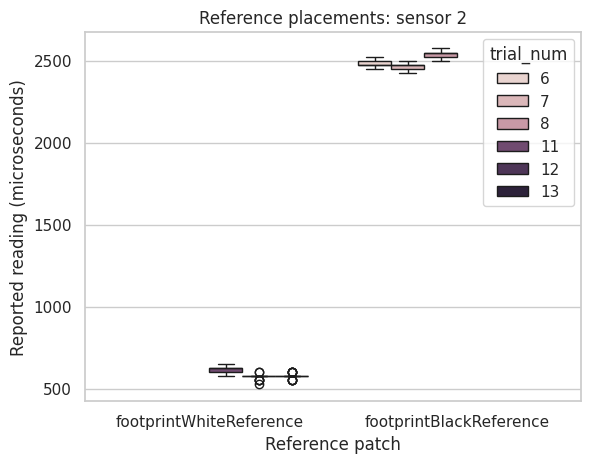

,test_name,trial_num,median_us,sd_us,samples
0,footprintBlackReference,6,2475.0,20.977393,50
1,footprintBlackReference,7,2475.0,22.525496,50
2,footprintBlackReference,8,2550.0,21.092604,50
3,footprintWhiteReference,11,625.0,17.280979,50
4,footprintWhiteReference,12,575.0,11.111678,50
5,footprintWhiteReference,13,575.0,11.834315,50


In [72]:
# 筛选目标传感器，并仅保留纯白和纯黑参考记录。
selected_references = reference_data.loc[
    (reference_data["sensor_num"] == SELECTED_SENSOR)
    & reference_data["test_name"].isin([WHITE_TEST_NAME, BLACK_TEST_NAME])
].copy()
# 按参考面和独立摆位分组，计算中位数、样本标准差（ddof=1）和样本数。
reference_summary = (
    selected_references.groupby(["test_name", "trial_num"], as_index=False)
    .agg(median_us=("sensor_reading", "median"),
         sd_us=("sensor_reading", "std"), samples=("sensor_reading", "size"))
)
# 用箱线图比较同一种参考面的不同摆位。
sns.boxplot(data=selected_references, x="test_name", y="sensor_reading", hue="trial_num")
plt.xlabel("Reference patch")
plt.ylabel("Reported reading (microseconds)")
plt.title(f"Reference placements: sensor {SELECTED_SENSOR}")
plt.show()
# 显示逐次摆位的统计结果。
reference_summary


In [73]:
# 对每种参考面的各次摆位中位数再取中位数。
reference_centres = reference_summary.groupby("test_name")["median_us"].median()
W = float(reference_centres[WHITE_TEST_NAME])
B = float(reference_centres[BLACK_TEST_NAME])
# 后续会除以 B − W，因此两个参考值必须有限且不同。
if not np.isfinite(W + B) or W == B:
    raise ValueError("Distinct, finite white and black references are needed.")
print(f"White reference W = {W:.1f} us; black reference B = {B:.1f} us")


White reference W = 575.0 us; black reference B = 2475.0 us


## 5. 确定用什么参考来比较

图上用固定的 W 和 B 作对照，分别代表大块纯白和纯黑上的典型读数。看看各条曲线离 B 有多近，并结合刚才看到的参考值波动。读数很少恰好等于 B。如果差异已经很明显，可以直接描述。

示例会在 B 的上下各 45 µs 画一个阴影带，这是用来演示允许差值（**容差**）的。对实测数据，保留 `MATCH_TOLERANCE_US = None`，图上只画参考线。若数值判定对你的实验有帮助，可以根据参考读数波动和摆位重复性设定容差。先确定容差，再判断各黑条是否达到黑参考，并对所有黑条使用同一设置。示例里的 45 µs 只用作演示。

解读平顶曲线时也要考虑饱和。传感器可能在整个感应范围都被黑条覆盖之前，就已达到读数上限。判断这种解释时，可参考前面的饱和实验。

In [74]:
# 示例容差为 ±45 µs，真车模式默认为 None。
MATCH_TOLERANCE_US = 45.0 if USE_EXAMPLE_DATA else None
epsilon = None
if MATCH_TOLERANCE_US is not None:
    if not 0 < MATCH_TOLERANCE_US < abs(B - W):
        raise ValueError("Choose a positive tolerance smaller than the white-to-black contrast, or leave it as None.")
    # 将微秒容差换算为归一化尺度上的容差。
    epsilon = MATCH_TOLERANCE_US / abs(B - W)
    print(f"Matching band: {1-epsilon:.3f} to {1+epsilon:.3f} in normalised units.")
else:
    print("Using W and B as reference lines, without a numerical matching band.")


Using W and B as reference lines, without a numerical matching band.


## 6. 绘制黑条横扫曲线

先用原始单位绘图，以便直接对应真车报告的读数。代码筛选指定的传感器和测试，再按传感器、线宽、方向、试次和位置分组。每组代表同一个停靠点静止采集的一批读数。用中位数表示该位置的典型响应，可以减少偶发高读数的影响。

每张图对应一种线宽，每条曲线代表一次独立横扫。竖直虚线标出实测黑条的两侧边缘，水平点线标出 W，水平虚线标出 B。如果设置了容差，阴影带显示 B 附近的允许范围。点是各批次的中位数，竖直误差棒是中位数加减一个样本标准差，表示该位置同批读数的波动。中位数的置信区间和横向定位误差需要另行估计。连线帮助阅读曲线，实际采样发生在标出的停靠点。

沿曲线从白底、跨过黑条、再回到白底。两侧是否都恢复到稳定白参考附近？最高响应在几个相邻位置都出现了，还是由于步长较大，峰值可能落在两个停靠点之间？比较重复横扫和两个方向的曲线。曲线若横向错开，可能说明重新摆位时的对齐不同，直接对各趟取平均会掩盖这一点。

保留异常曲线，检查原始读数和采集顺序。如果峰值附近采样不够密，可以在定位装置允许的范围内缩小步长。漏采峰值会让原本可能达到黑参考的黑条看起来响应偏低。

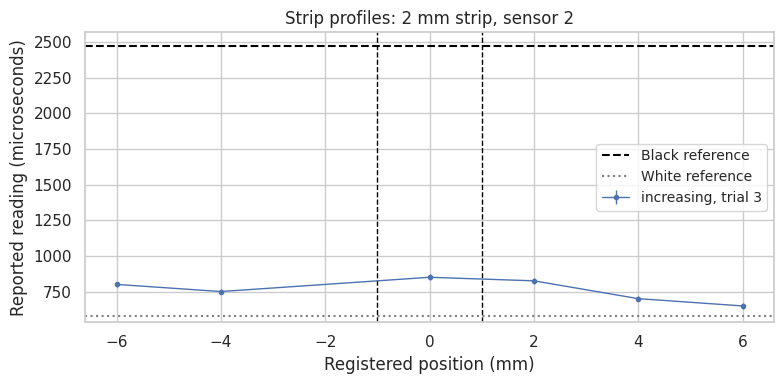

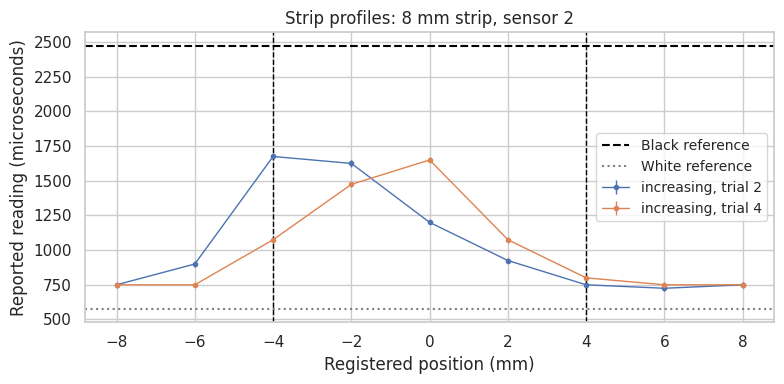

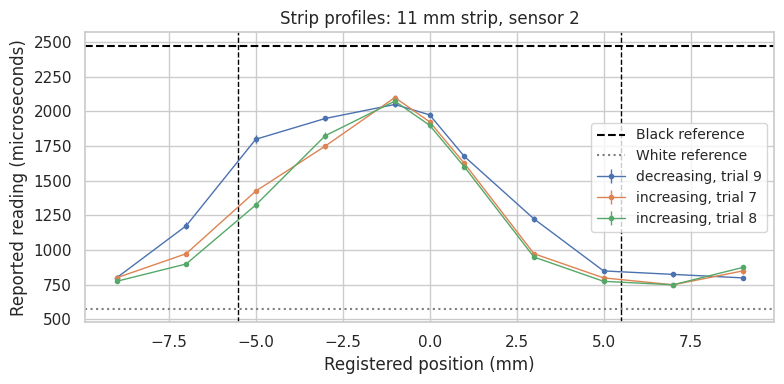

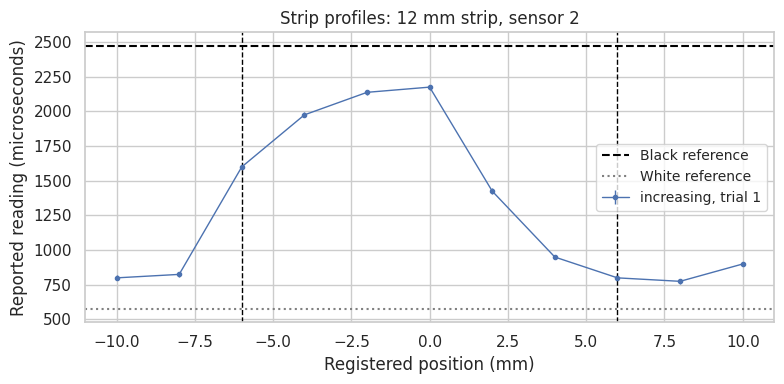

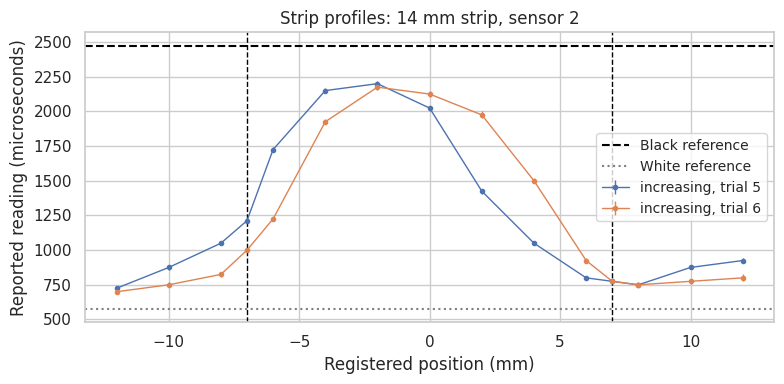

In [75]:
# 筛选指定的黑条测试和传感器。
selected_raw = data.loc[
    (data["test_name"] == TEST_NAME) & (data["sensor_num"] == SELECTED_SENSOR)
].copy()
# 同一组线宽、方向和试次得到一条曲线，增加位置字段后得到一个停靠点。
profile_keys = ["sensor_num", "rectangle_width_mm", "direction", "trial_num"]
batch_keys = profile_keys + ["position_mm"]
# 用位置上的批次中位数画点，用样本标准差画误差棒。
scan_summary = (
    selected_raw.groupby(batch_keys, as_index=False)
    .agg(reading_us=("sensor_reading", "median"),
         sd_us=("sensor_reading", "std"), samples=("sensor_reading", "size"))
)
if scan_summary.empty:
    raise ValueError("No strip rows to plot: check the test/sensor labels.")
# 每种线宽单独画图，每个方向和试次保留独立曲线。
for width_mm, profiles in scan_summary.groupby("rectangle_width_mm"):
    fig, ax = plt.subplots(figsize=(8, 4))
    for (direction, trial), profile in profiles.groupby(["direction", "trial_num"]):
        # 按位置坐标排图，正扫和反扫都沿同一空间轴显示。
        profile = profile.sort_values("position_mm")
        ax.errorbar(profile["position_mm"], profile["reading_us"],
                    yerr=profile["sd_us"], marker=".", linewidth=1,
                    label=f"{direction}, trial {trial}")
    # 画黑参考线，若已设容差则加阴影带。
    ax.axhline(B, color="black", linestyle="--", label="Black reference")
    if MATCH_TOLERANCE_US is not None:
        ax.axhspan(B - MATCH_TOLERANCE_US, B + MATCH_TOLERANCE_US, alpha=0.15, color="grey")
    # 画白参考线，并标出相对中心的两侧黑条边缘。
    ax.axhline(W, color="grey", linestyle=":", label="White reference")
    for edge in [-width_mm / 2, width_mm / 2]:
        ax.axvline(edge, color="black", linestyle="--", linewidth=1)
    ax.set(title=f"Strip profiles: {width_mm:g} mm strip, sensor {SELECTED_SENSOR}",
           xlabel="Registered position (mm)", ylabel="Reported reading (microseconds)")
    ax.legend(fontsize="small")
    plt.tight_layout()
    plt.show()


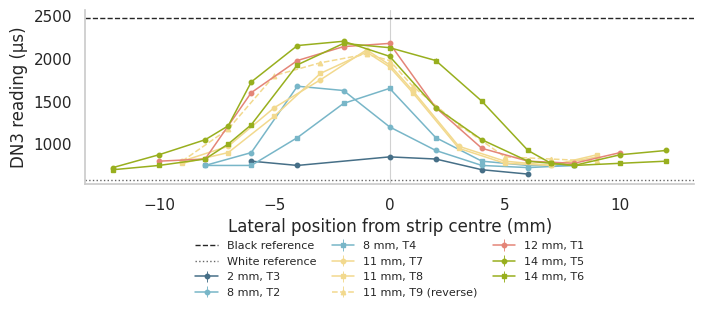

In [79]:
fig, ax = plt.subplots(figsize=(7.2, 3.55))

width_groups = scan_summary.groupby("rectangle_width_mm")
colours = ["#466F87", "#78B6C8", "#F2D98E", "#E48578", "#98AF1E"]
markers = ["o", "s", "^"]

for colour_index, (width_mm, profiles) in enumerate(width_groups):
    for repeat, ((trial, direction), profile) in enumerate(
        profiles.groupby(["trial_num", "direction"])
    ):
        profile = profile.sort_values("position_mm")
        reverse = direction == "decreasing"
        suffix = " (reverse)" if reverse else ""

        ax.errorbar(
            profile["position_mm"],
            profile["reading_us"],
            yerr=profile["sd_us"],
            color=colours[colour_index],
            marker=markers[repeat % len(markers)],
            markersize=3.2,
            linewidth=1.1,
            elinewidth=0.65,
            linestyle="--" if reverse else "-",
            label=f"{width_mm:g} mm, T{trial}{suffix}",
        )

if MATCH_TOLERANCE_US is not None:
    ax.axhspan(
        B - MATCH_TOLERANCE_US,
        B + MATCH_TOLERANCE_US,
        alpha=0.15,
        color="grey",
    )

ax.grid(False, which="both", axis="both")
ax.axvline(0, color="0.82", linewidth=0.8, zorder=0)
ax.axhline(B, color="0.15", linestyle="--", linewidth=1, label="Black reference")
ax.axhline(W, color="0.4", linestyle=":", linewidth=1, label="White reference")

ax.set(
    xlabel="Lateral position from strip centre (mm)",
    ylabel="DN3 reading (µs)",
)
ax.spines[["top", "right"]].set_visible(False)

ax.legend(
    ncol=3,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.27),
    frameon=False,
    fontsize=8,
    columnspacing=1.4,
)

fig.tight_layout()
plt.show()

## 7. 比较每趟横扫的峰值响应

每趟横扫记录了传感器在各个位置的响应。现在要比较的是，每趟横扫的最强典型响应达到了多少黑白对比。先对各位置的一批读数取中位数，再从这些位置的中位数中找出最高的归一化响应，作为该趟的**峰值响应**。比较不同线宽的峰值，可以看出窄条是否响应较弱。保留每一趟测量，也能看出这个结果是否容易复现。

**归一化**将固定的白参考映射到 0，将固定的黑参考映射到 1：

$$z(x)=\frac{R(x)-W}{B-W}$$

\(R(x)\) 是位置 \(x\) 的批次中位数。减去 W 得到相对白参考的变化，再除以 B − W，将变化表示成实测黑白对比差的一部分。例如，W = 300 µs、B = 1700 µs、R = 860 µs 时，\(z=0.4\)，即达到实测黑白对比差的 40%。要从响应推断黑色覆盖面积，仍需要一个能描述覆盖面积和读数关系的模型。

这样可以用同一条黑参考线 \(z=1\) 比较各条黑条的峰值。如果每个传感器都用各自的参考值，这个尺度也便于比较不同传感器。也可以直接用微秒判断峰值是否接近黑参考。归一化只改读数尺度，位置和平台宽度保持原样，原数据中的噪声、非线性和饱和也仍会体现在结果中。

同一个传感器在同样条件下测的所有黑条，使用同一组 W 和 B。如果每条各用自己的峰值做缩放，弱响应也会变成 1，失去比较意义。保留小于 0 或大于 1 的表格值，它们可能反映读数波动或条件变化。即使 W 和 B 的数值大小顺序反过来，公式仍会将白映射到 0、黑映射到 1。

下面的第一个单元格增加 `response` 列，再为每趟横扫找出归一化后最高的批次中位数。记下峰值对应的位置，并和步骤 6 的曲线核对，确认采样是否足以捕捉峰值。散点图中每个点代表一趟独立横扫，\(z=1\) 的水平线代表黑参考。设定容差后，阴影带和状态列会应用你选的规则。未设容差时，状态列显示 `not assessed`，可以根据图描述各条响应。比较时保留方向和试次，并检查异常高的峰值。

In [76]:
# 用固定 W、B 归一化各位置的批次中位数。
scan_summary["response"] = (scan_summary["reading_us"] - W) / (B - W)
# 找每趟横扫最大归一化响应所在的行，以保留其峰值位置。
peak_indices = scan_summary.groupby(profile_keys)["response"].idxmax()
peak_summary = scan_summary.loc[peak_indices].copy().reset_index(drop=True)
# 未设置容差时标记为未判定，否则按容差带给出比较结果。
peak_summary["peak_status"] = "not assessed"
if epsilon is not None:
    peak_summary["peak_status"] = np.select(
        [peak_summary["response"] < 1 - epsilon,
         peak_summary["response"] > 1 + epsilon],
        ["below", "above band"], default="matches")
peak_summary[profile_keys + ["position_mm", "reading_us", "response", "peak_status"]]


,sensor_num,rectangle_width_mm,direction,trial_num,position_mm,reading_us,response,peak_status
0,2,2.0,increasing,3,0.0,850.0,0.144737,not assessed
1,2,8.0,increasing,2,-4.0,1675.0,0.578947,not assessed
2,2,8.0,increasing,4,0.0,1650.0,0.565789,not assessed
3,2,11.0,decreasing,9,-1.0,2050.0,0.776316,not assessed
4,2,11.0,increasing,7,-1.0,2100.0,0.802632,not assessed
5,2,11.0,increasing,8,-1.0,2074.0,0.788947,not assessed
6,2,12.0,increasing,1,0.0,2175.0,0.842105,not assessed
7,2,14.0,increasing,5,-2.0,2200.0,0.855263,not assessed
8,2,14.0,increasing,6,-2.0,2175.0,0.842105,not assessed


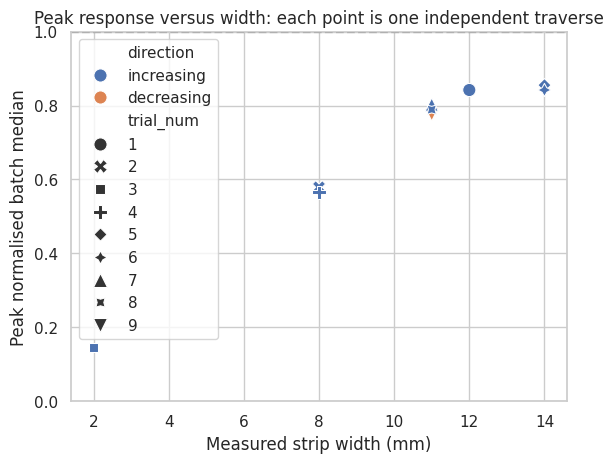

In [77]:
# 每个点是一趟独立横扫的峰值，颜色表示方向，标记形状表示试次。
sns.scatterplot(data=peak_summary, x="rectangle_width_mm", y="response",
                hue="direction", style="trial_num", s=90)
if epsilon is not None:
    plt.axhspan(1 - epsilon, 1 + epsilon, color="grey", alpha=0.2, label="Black-match band")
# 归一化响应 1 对应黑参考线。
plt.axhline(1, color="black", linestyle="--")
plt.xlabel("Measured strip width (mm)")
plt.ylabel("Peak normalised batch median")
# 原图只显示 0 到 1，越界的实测结果可在上一个单元格的表里查看。
plt.ylim(0, 1)
plt.title("Peak response versus width: each point is one independent traverse")
plt.legend()
plt.show()


## 8. 解释黑条对比结果

把横扫曲线和峰值图结合起来看。哪条黑条的峰值偏低？哪条更接近大块纯黑的参考值？较宽的条上有没有平台？如果能从数据中指出看起来达到 B 的最窄已测黑条，可以同时指出一条测过且响应仍低于 B 的更窄黑条。如果波动让你难以明确判定，可以写「看起来接近黑参考」。

选一个重要现象，重新摆位后再扫一次。先写下你的预期，再把两次结果保留在图上比较。若结果有差异，可检查对齐、停稳时间或参考读数的变化。一次独立重复是有用的初步检验，主要活动没有规定每个方向都扫三次。结论仍不清楚时，可以多做几次。

写一个简短结论，说明传感器和所测线宽，指出图中支持解释的一项特征，交代复测结果和一个局限。窄条的峰值较低，与感应范围内仍有白底贡献的解释相符。达到 B 时，尤其在可能饱和的情况下，仍难以据此确定精确的光学感应范围。

**练习到此结束。** 保留原始文件、图和解释。如果有现象仍未确定，清楚说明现有数据支持到哪一步即可。